## Preparing Input Data and Network

Before implementing OD-based route variability, the routing inputs must be prepared carefully.

In this step we are performing four tasks:

1. Load the cleaned consolidated dataset which is version v2
2. Select a representative routing subset
3. Build the bicycle network used for routing
4. Map trip origins and destinations to the nearest network nodes

This verification step is important because route variability can only be tested meaningfully if the baseline routing inputs are valid.

In [1]:
import pandas as pd
import osmnx as ox
import networkx as nx

# 1. Load cleaned dataset
df = pd.read_csv("citi_bike_2025_cleaned_consolidated_v2.csv")

# 2. Restore datetime columns after reading CSV
df["started_at"] = pd.to_datetime(df["started_at"])
df["ended_at"] = pd.to_datetime(df["ended_at"])

# 3. Create a representative sample for routing experiments
route_sample = df.sample(100000, random_state=42).copy()
route_sample = route_sample.sample(10000, random_state=42).copy().reset_index(drop=True)

# 5. Build routing graph
places = [
    "Jersey City, New Jersey, USA",
    "Hoboken, New Jersey, USA"
]

G = ox.graph_from_place(places, network_type="bike")

# 6. Keep only the largest connected component
largest_cc = max(nx.connected_components(G.to_undirected()), key=len)
G = G.subgraph(largest_cc).copy()

# 7. Map OD coordinates to nearest graph nodes
orig_nodes = ox.distance.nearest_nodes(
    G,
    X=route_sample["start_lng"],
    Y=route_sample["start_lat"]
)

dest_nodes = ox.distance.nearest_nodes(
    G,
    X=route_sample["end_lng"],
    Y=route_sample["end_lat"]
)

print("Trips in routing sample:", len(route_sample))
print("Nodes in routing graph:", len(G.nodes))
print("Edges in routing graph:", len(G.edges))
print("Mapped origin nodes:", len(orig_nodes))
print("Mapped destination nodes:", len(dest_nodes))

Trips in routing sample: 10000
Nodes in routing graph: 6164
Edges in routing graph: 14676
Mapped origin nodes: 10000
Mapped destination nodes: 10000


In [2]:
baseline_failed = 0

for i, (o, d) in enumerate(zip(orig_nodes, dest_nodes)):
    try:
        nx.shortest_path(G, o, d, weight="length")
    except:
        baseline_failed += 1
        print(f"Trip index {i} failed: Start Node {o} -> End Node {d}")

print("Baseline failed routes:", baseline_failed)

Baseline failed routes: 0


In [3]:
try:
    nx.shortest_path(G, 12097469455, 42437410, weight="length")
    print("Path exists in REVERSE! It's a one-way street direction issue.")
except:
    print("No path exists either way. This node is truly an isolated island.")

No path exists either way. This node is truly an isolated island.


In [4]:
import geopandas as gpd

orig_gdf = gpd.GeoDataFrame(
    route_sample,
    geometry=gpd.points_from_xy(route_sample["start_lng"], route_sample["start_lat"]),
    crs="EPSG:4326"
)

dest_gdf = gpd.GeoDataFrame(
    route_sample,
    geometry=gpd.points_from_xy(route_sample["end_lng"], route_sample["end_lat"]),
    crs="EPSG:4326"
)

In [5]:
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)

In [6]:
orig_web = orig_gdf.to_crs(epsg=3857)
dest_web = dest_gdf.to_crs(epsg=3857)
edges_web = edges_gdf.to_crs(epsg=3857)

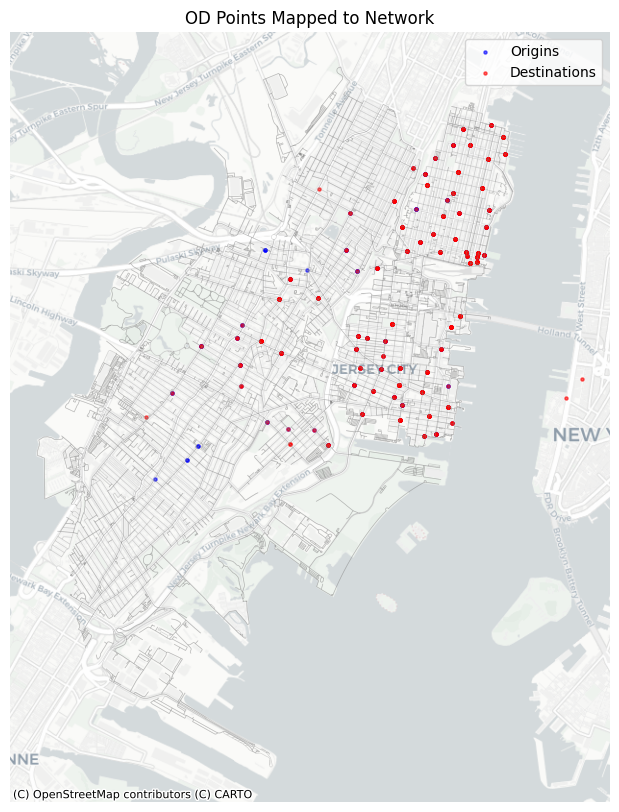

In [7]:
import matplotlib.pyplot as plt
import contextily as ctx

fig, ax = plt.subplots(figsize=(10,10))

# Plot network
edges_web.plot(ax=ax, linewidth=0.5, alpha=0.3, color="gray")

# Plot origins
orig_web.sample(500).plot(
    ax=ax,
    color="blue",
    markersize=5,
    alpha=0.6,
    label="Origins"
)

# Plot destinations
dest_web.sample(500).plot(
    ax=ax,
    color="red",
    markersize=5,
    alpha=0.6,
    label="Destinations"
)

# Add basemap
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("OD Points Mapped to Network")
ax.legend()
ax.axis("off")

plt.show()

### Verification

The baseline routing step was checked before implementing variability. This is necessary because failures in the baseline routing would indicate problems in the network coverage, node mapping, or graph connectivity rather than in the variability method itself.

adding to that there may be situation when one of the baseline route may fail due to as we can see in the map so one of the trips might be assigned to a node that lived on an "Island."  like destination in newyork When i deleted the islands from the graph, that trip was left pointing to a node that no longer has any roads connected to it.

So, Only after confirming that baseline routing works reliably does it make sense to introduce OD-based route variation properly.

## Step 2 — OD-Based Circle Method with Validation

To introduce realistic variability, an intermediate point is selected within a circular region defined by the origin–destination pair.

However, since routing operates on a network, not all points in geographic space are valid for routing. Therefore, a validation step is introduced:

- A random point is sampled inside the OD-based circle
- The point is mapped to the nearest network node
- Connectivity is checked between origin → intermediate → destination
- If routing is not feasible, a new point is sampled (retry mechanism)

This ensures that variability remains realistic while maintaining valid routing paths.

In [8]:
import numpy as np
import random

def random_point_in_circle(lat1, lon1, lat2, lon2):
    # Step 1: find midpoint
    center_lat = (lat1 + lat2) / 2
    center_lon = (lon1 + lon2) / 2

    # Step 2: approximate radius
    radius_lat = abs(lat1 - lat2) / 2
    radius_lon = abs(lon1 - lon2) / 2

    # Step 3: random polar coordinates
    r = np.sqrt(np.random.rand())
    theta = 2 * np.pi * np.random.rand()

    # Step 4: generate point
    rand_lat = center_lat + r * radius_lat * np.cos(theta)
    rand_lon = center_lon + r * radius_lon * np.sin(theta)

    return rand_lat, rand_lon

In [9]:
import networkx as nx

circle_routes = []
baseline_routes = []
failed_circle = 0
success_circle = 0

variable_routes = 0
shortest_routes = 0

MAX_RETRIES = 5

for i, row in route_sample.iterrows():
    o = orig_nodes[i]
    d = dest_nodes[i]

    try:
        base_route = nx.shortest_path(G, o, d, weight="length")
        baseline_routes.append(base_route)
    except:
        circle_routes.append(None)
        failed_circle += 1
        continue

    route_found = False
    used_variability = False   # for tracking

    # Apply variability 30% of the time
    if random.random() < 0.3:

        for attempt in range(MAX_RETRIES):

            lat_mid, lon_mid = random_point_in_circle(
                row["start_lat"], row["start_lng"],
                row["end_lat"], row["end_lng"]
            )

            try:
                mid_node = ox.distance.nearest_nodes(G, X=lon_mid, Y=lat_mid)

                # VALIDATION STEP
                if nx.has_path(G, o, mid_node) and nx.has_path(G, mid_node, d):

                    r1 = nx.shortest_path(G, o, mid_node, weight="length")
                    r2 = nx.shortest_path(G, mid_node, d, weight="length")

                    route = r1 + r2[1:]
                    route_found = True
                    used_variability = True
                    break

            except:
                continue

    if not route_found:
        route = base_route  # fallback

    # count routes
    if used_variability:
        variable_routes += 1
    else:
        shortest_routes +=1
        
    circle_routes.append(route)
    success_circle += 1

print("\nFinal Statistics:")
print("Total routes:", len(circle_routes))
print("Successful routes:", success_circle)
print("Failed routes:", failed_circle)

print("\nRoute Type Breakdown:")
print("Variable routes:", variable_routes)
print("Shortest path routes:", shortest_routes)
print("\nBaseline routes stored:", len(baseline_routes))


Final Statistics:
Total routes: 10000
Successful routes: 10000
Failed routes: 0

Route Type Breakdown:
Variable routes: 2941
Shortest path routes: 7059

Baseline routes stored: 10000


## Preparing Route and Station Layers for Visualization

Before creating comparison maps, the route outputs must be converted into GeoDataFrames.

This step prepares three spatial layers:

1. Baseline routes (shortest path only)
2. Final routes after OD-constrained variability
3. Station locations

All layers are converted to EPSG:3857 so that they can be displayed correctly on a web basemap.

In [10]:
import geopandas as gpd
from shapely.geometry import LineString

def routes_to_gdf(routes, G):
    geometries = []

    for route in routes:
        if route is None or len(route) < 2:
            continue

        coords = [(G.nodes[n]["x"], G.nodes[n]["y"]) for n in route]

        if len(coords) > 1:
            geometries.append(LineString(coords))

    return gpd.GeoDataFrame(geometry=geometries, crs="EPSG:4326")

In [11]:
baseline_gdf = routes_to_gdf(baseline_routes, G)
circle_gdf = routes_to_gdf(circle_routes, G)

print("Baseline route geometries:", len(baseline_gdf))
print("Final route geometries:", len(circle_gdf))

Baseline route geometries: 10000
Final route geometries: 10000


In [13]:
# Convert all layers to Web Mercator (required for contextily)

baseline_web = baseline_gdf.to_crs(epsg=3857)
circle_web = circle_gdf.to_crs(epsg=3857)

print("Conversion to web CRS done.")

Conversion to web CRS done.


## Baseline Routing (Shortest Path Only)

This map shows all routes generated using the shortest path algorithm.

In this scenario, all trips follow the most optimal path between origin and destination, resulting in highly concentrated flows along specific corridors.

This serves as a reference to compare against the variability-based routing.

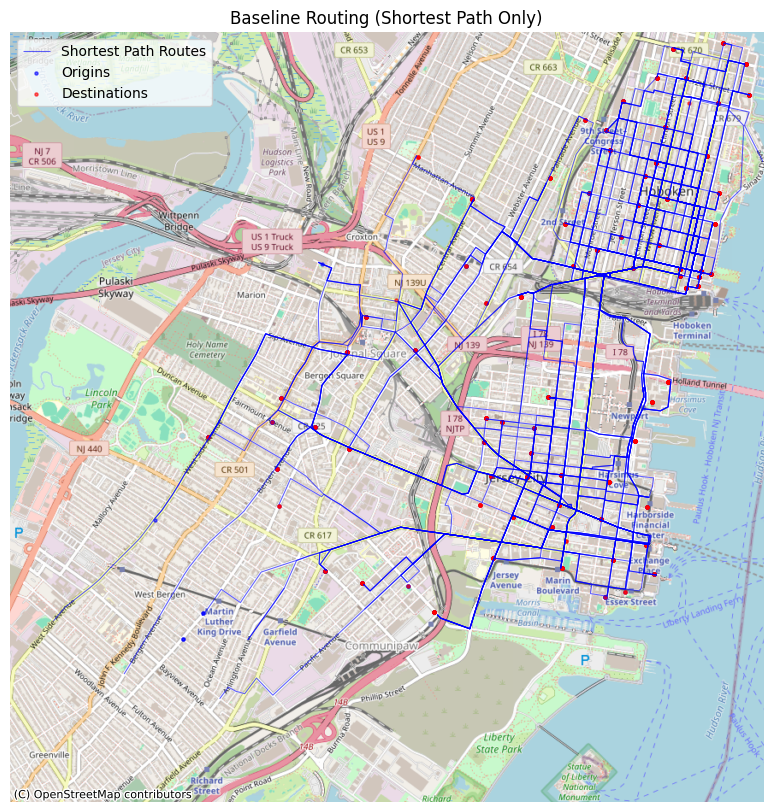

In [14]:
import matplotlib.pyplot as plt
import contextily as ctx

fig, ax = plt.subplots(figsize=(10, 10))

sample_size = min(300, len(baseline_web))

# -------- SHORTEST ROUTES --------
baseline_web.sample(sample_size).plot(
    ax=ax,
    linewidth=0.8,
    alpha=0.6,
    color="blue",
    label="Shortest Path Routes"
)

# Plot origins
orig_web.sample(500).plot(
    ax=ax,
    color="blue",
    markersize=5,
    alpha=0.6,
    label="Origins"
)

# Plot destinations
dest_web.sample(500).plot(
    ax=ax,
    color="red",
    markersize=5,
    alpha=0.6,
    label="Destinations"
)

# SAME bounds (important)
ax.set_xlim(baseline_web.total_bounds[[0, 2]])
ax.set_ylim(baseline_web.total_bounds[[1, 3]])

# basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)

ax.set_title("Baseline Routing (Shortest Path Only)")
ax.axis("off")
ax.legend()

plt.show()

## Routing without OD-Constrained Variability

This map shows routes before introducing OD-based variability.

Approximately all shortest trips are included in this plot which we are calling baseline routes.

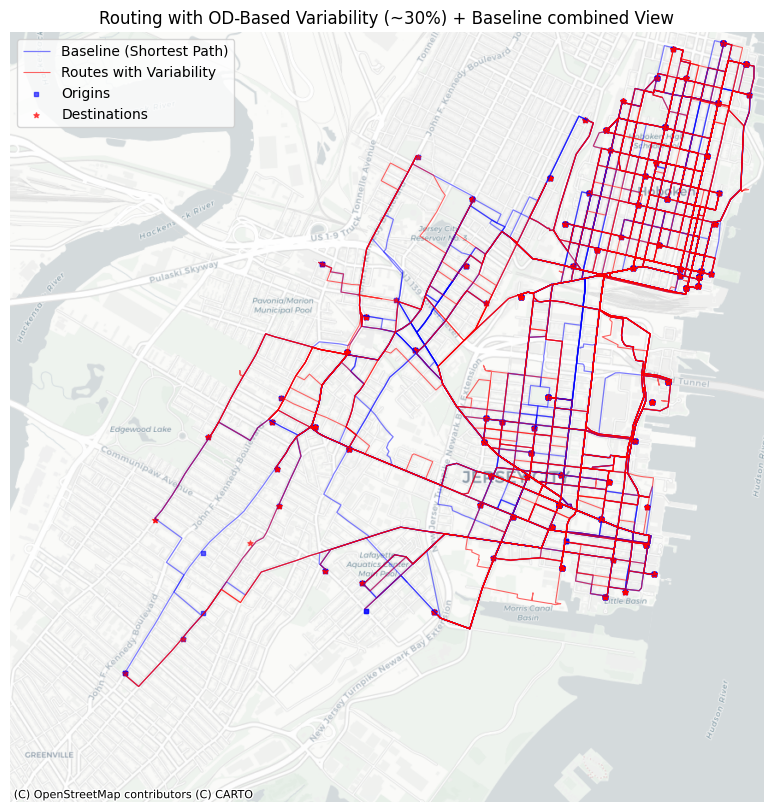

In [20]:
fig, ax = plt.subplots(figsize=(10, 10))

sample_size = min(300, len(circle_web))

# -------- BASELINE ROUTES (background) --------
baseline_web.sample(min(400, len(baseline_web))).plot(
    ax=ax,
    linewidth=0.9,
    alpha=0.5,
    color="blue",
    label="Baseline (Shortest Path)"
)
# -------- MIXED ROUTES --------
circle_web.sample(sample_size).plot(
    ax=ax,
    linewidth=0.8,
    alpha=0.6,
    color="red",
    label="Routes with Variability"
)

# Plot origins
orig_web.sample(500).plot(
    ax=ax,
    color="blue",
    marker="s",      # 's' stands for square
    markersize=10,
    alpha=0.6,
    label="Origins"
)

# Plot destinations
dest_web.sample(500).plot(
    ax=ax,
    color="red",
    marker="*",
    markersize=15,
    alpha=0.6,
    label="Destinations"
)

# SAME bounds (very important)
ax.set_xlim(baseline_web.total_bounds[[0, 2]])
ax.set_ylim(baseline_web.total_bounds[[1, 3]])

# basemap
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Routing with OD-Based Variability (~30%) + Baseline combined View")
ax.axis("off")
ax.legend()

plt.show()

## Combined Visualization of Routing Approaches

This map presents both baseline and variability-based routing in a single visualization.

- Blue lines represent baseline shortest-path routes
- Red lines represent routes incorporating OD-constrained variability
- Blue square and Red start  points indicate station locations origin and destination and vice versa.

The comparison shows that shortest-path routing leads to strong overlap along specific corridors, while the variability approach introduces dispersion and alternative paths.

This demonstrates that OD-based variability improves the realism of simulated mobility patterns while preserving logical routing structure.

In [21]:
circle_gdf.to_file("routes_with_variability.gpkg", driver="GPKG")
circle_gdf.to_file("routes_with_variability.geojson", driver="GeoJSON")

## Data Storage Format

The routed trajectories were saved in both GeoPackage (.gpkg) and GeoJSON formats.

GeoPackage was used for analysis due to its efficiency and support for large datasets, while GeoJSON was created for easy sharing and visualization purposes.

This ensures both computational efficiency and accessibility.

# Task 3 - Traffic flows

After routing individual trips, the next step is to move from single trajectories to aggregated traffic flows. Aggregation allows us to identify commonly used corridors, spatial patterns of movement, and temporal variations in travel demand.

During this stage, i will...

Select an appropriate spatial unit for aggregation, such as:
road network elements (e.g. OpenStreetMap street segments) or
a regular grid (e.g. square or hexagonal cells)
Aggregate routed trajectories into traffic flows by counting how many trips intersect or traverse each spatial unit
Optionally incorporate temporal aggregation (e.g. by hour of day, weekday vs weekend, or peak vs off-peak periods)
Clearly describe and justify my aggregation choices, including spatial resolution and temporal grouping
The level of aggregation should be chosen such that spatial patterns are visible while remaining computationally manageable.

## Step 1 — Loading Routed Trajectories

The routed trajectories generated in the previous stage are loaded for traffic flow analysis.

Each route represents an individual trip as a LineString geometry. These trajectories will be used to compute aggregated traffic flows on the road network.

This approach avoids recomputing routes and ensures consistency between routing and flow analysis.

In [26]:
import geopandas as gpd

routes_gdf = gpd.read_file("routes_with_variability.gpkg")

print("Loaded routes:", len(routes_gdf))
routes_gdf.head()

Loaded routes: 10000


,geometry
0,"LINESTRING (-74.03022 40.73586, -74.03037 40.7..."
1,"LINESTRING (-74.02918 40.7359, -74.02899 40.73..."
2,"LINESTRING (-74.03454 40.74445, -74.03547 40.7..."
3,"LINESTRING (-74.027 40.7431, -74.02745 40.7431..."
4,"LINESTRING (-74.03842 40.74781, -74.03712 40.7..."


## Step 2 — Converting Routes into Network Edges

To compute traffic flows, individual routes must be decomposed into the road segments (edges) they traverse.

Each route is represented as a sequence of nodes, which can be broken into consecutive node pairs representing edges.

By extracting these edges from all routes, we can count how many times each road segment is used across all trips.

In [27]:
from collections import Counter

edge_counter = Counter()

for route in circle_routes:   # use your in-memory routes (best)
    if route is None or len(route) < 2:
        continue

    for u, v in zip(route[:-1], route[1:]):
        edge_counter[(u, v)] += 1

In [29]:
print("Total unique edges used:", len(edge_counter))
print("Sample edge counts:", list(edge_counter.items())[:5])

Total unique edges used: 5631
Sample edge counts: [((np.int64(5451987123), 297110085), 238), ((297110085, 297110097), 206), ((297110097, 7217917595), 206), ((7217917595, 103866250), 207), ((103866250, 4988900669), 78)]


## interpretation

so , finally we got total unique edges used are : 5631 

## Step 3 — Creating Edge-Level Flow Dataset

The aggregated edge counts are converted into a GeoDataFrame by mapping each edge to its corresponding geometry in the road network.

Each row represents a road segment with an associated flow value, indicating how many trips traversed that segment.

This dataset forms the basis for traffic flow visualization and analysis.

In [30]:
import geopandas as gpd

edge_rows = []

for (u, v), count in edge_counter.items():
    if G.has_edge(u, v):
        edge_data = G.get_edge_data(u, v)

        # Handle MultiDiGraph (multiple edges possible)
        edge = edge_data[0]

        geom = edge.get("geometry", None)

        if geom is None:
            # fallback: straight line
            point_u = (G.nodes[u]["x"], G.nodes[u]["y"])
            point_v = (G.nodes[v]["x"], G.nodes[v]["y"])
            from shapely.geometry import LineString
            geom = LineString([point_u, point_v])

        edge_rows.append({
            "u": u,
            "v": v,
            "total_flow": count,
            "geometry": geom
        })

flow_gdf = gpd.GeoDataFrame(edge_rows, crs="EPSG:4326")

print("Flow edges created:", len(flow_gdf))
flow_gdf.head()

Flow edges created: 5631


,u,v,total_flow,geometry
0,5451987123,297110085,238,"LINESTRING (-74.03022 40.73586, -74.03032 40.7..."
1,297110085,297110097,206,"LINESTRING (-74.03037 40.73546, -74.03038 40.7..."
2,297110097,7217917595,206,"LINESTRING (-74.0309 40.73551, -74.03115 40.73..."
3,7217917595,103866250,207,"LINESTRING (-74.03115 40.73555, -74.03128 40.7..."
4,103866250,4988900669,78,"LINESTRING (-74.03146 40.73561, -74.03143 40.7..."


In [31]:
flow_gdf_web = flow_gdf.to_crs(epsg=3857)

In [32]:
print(flow_gdf["total_flow"].describe())

count    5631.000000
mean       41.888830
std        70.981193
min         1.000000
25%         2.000000
50%         8.000000
75%        51.000000
max       606.000000
Name: total_flow, dtype: float64


## Flow Distribution Analysis

The distribution of traffic flows across road segments is highly skewed.

- Most segments have low flow values (median ≈ 8)
- A small number of segments carry very high traffic (up to 606 trips)

This indicates that bicycle traffic is concentrated along a limited number of main corridors, while most streets experience relatively low usage.

Such a pattern is consistent with real-world urban mobility behavior.

## Step 4 — Traffic Flow Visualization

Traffic flows are visualized by mapping each road segment with a color and thickness proportional to the number of trips.

This allows identification of high-demand corridors and spatial patterns of bicycle movement.

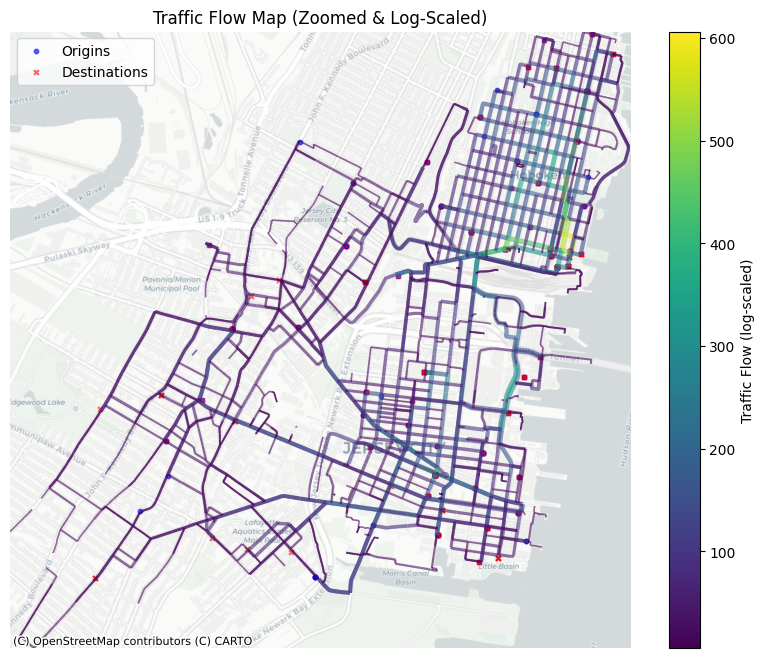

In [37]:
import matplotlib.pyplot as plt
import contextily as ctx
import numpy as np

fig, ax = plt.subplots(figsize=(10,10))

# -------- FILTER FLOWS --------
flow_plot = flow_gdf_web[flow_gdf_web["total_flow"] > 5]

# -------- PLOT FLOWS --------
flow_plot.plot(
    ax=ax,
    column='total_flow',
    cmap='viridis',
    linewidth=np.log1p(flow_plot['total_flow']) * 0.6,
    alpha=0.6,
    legend=True,
    legend_kwds={
        'label': 'Traffic Flow (log-scaled)',
        'orientation': 'vertical',
        'pad': 0.05,
        'shrink': 0.8
    }
)

# -------- ORIGINS --------
orig_web.sample(min(150, len(orig_web))).plot(
    ax=ax,
    color="blue",
    marker="o",
    markersize=10,
    alpha=0.6,
    label="Origins"
)

# -------- DESTINATIONS --------
dest_web.sample(min(150, len(dest_web))).plot(
    ax=ax,
    color="red",
    marker="x",
    markersize=12,
    alpha=0.6,
    label="Destinations"
)

# -------- ZOOM --------
bounds = flow_plot.total_bounds
ax.set_xlim([bounds[0], bounds[2]])
ax.set_ylim([bounds[1], bounds[3]])

# -------- BASEMAP --------
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Traffic Flow Map (Zoomed & Log-Scaled)")
ax.axis("off")
ax.legend()

plt.show()

In [38]:
stations_web = pd.concat([orig_web, dest_web])

## Step 5 — Comparison: Raw vs Log-Scaled Traffic Flows

Due to the highly skewed distribution of traffic flows, raw visualization tends to highlight only a few high-flow segments, while most of the network remains visually indistinct.

To address this, a log transformation is applied to the flow values.

The comparison below illustrates how log scaling improves the visibility of both high- and low-flow segments, resulting in a more interpretable map.

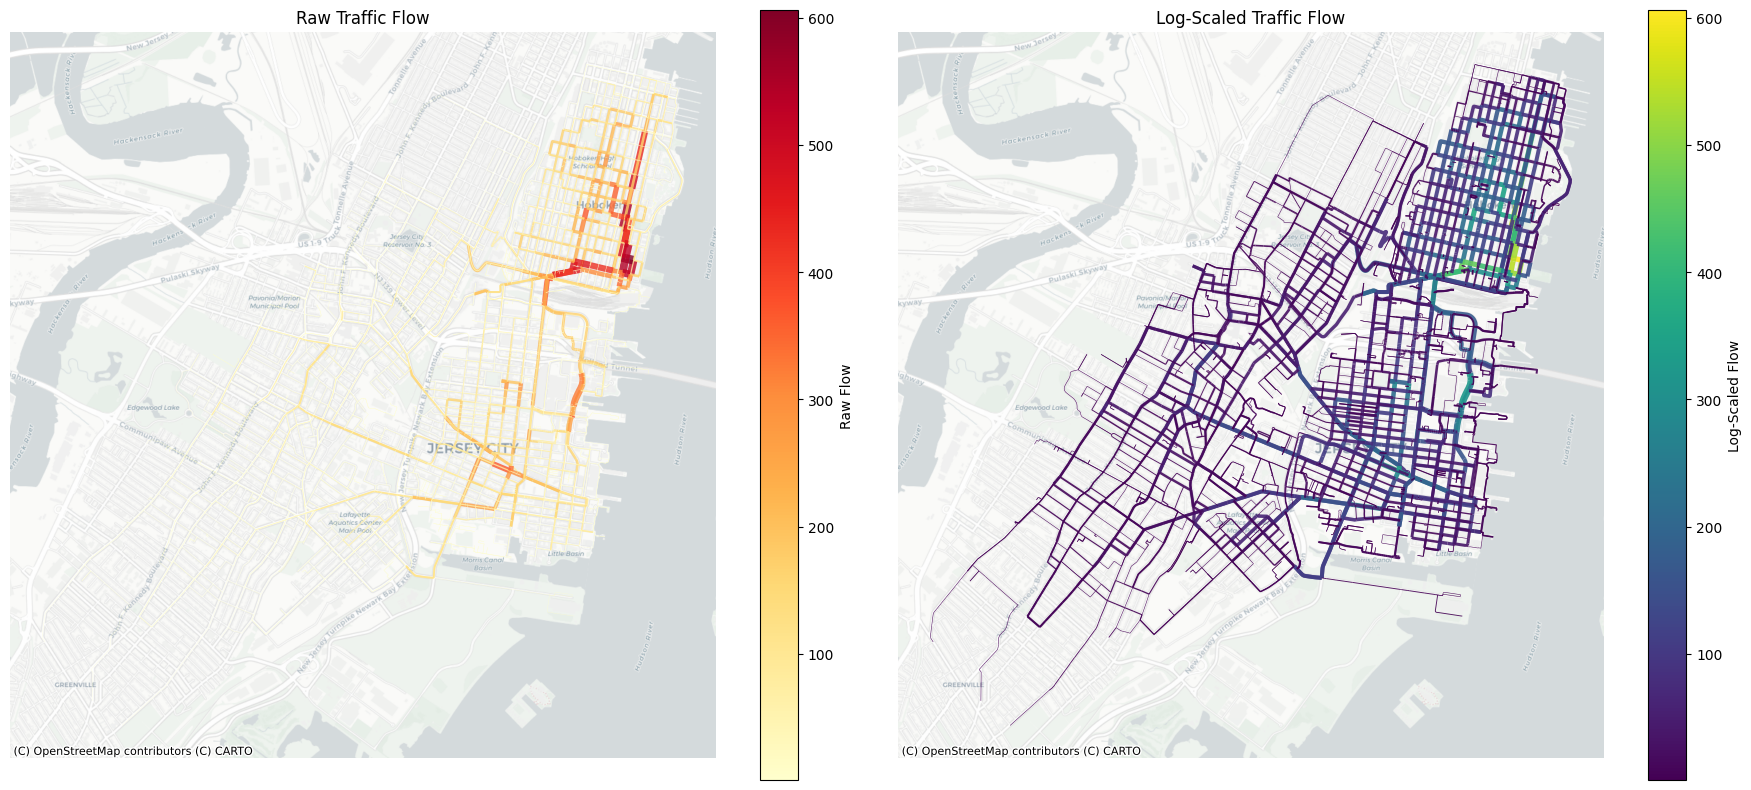

In [40]:
import matplotlib.pyplot as plt
import contextily as ctx
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# -------- RAW FLOW --------
flow_gdf_web.plot(
    ax=axes[0],
    column='total_flow',
    cmap='YlOrRd',
    linewidth=flow_gdf_web['total_flow'] * 0.01 + 0.2,
    alpha=0.8,
    legend=True,
    legend_kwds={'label': 'Raw Flow'}
)

ctx.add_basemap(axes[0], source=ctx.providers.CartoDB.Positron)
axes[0].set_title("Raw Traffic Flow")
axes[0].axis("off")

# -------- LOG FLOW --------
flow_gdf_web.plot(
    ax=axes[1],
    column='total_flow',
    cmap='viridis',
    linewidth=np.log1p(flow_gdf_web['total_flow']) * 0.6,
    alpha=0.9,
    legend=True,
    legend_kwds={'label': 'Log-Scaled Flow'}
)

ctx.add_basemap(axes[1], source=ctx.providers.CartoDB.Positron)
axes[1].set_title("Log-Scaled Traffic Flow")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Interpretation

The raw flow visualization is dominated by a small number of high-traffic segments, making it difficult to observe patterns across the broader network.

In contrast, the log-scaled visualization reveals a more balanced representation, where both major and minor routes are visible.

This demonstrates that log scaling is essential when working with skewed mobility data.

In [42]:
print(routes_gdf.columns)

Index(['geometry'], dtype='str')


In [43]:
routes_gdf["started_at"] = route_sample["started_at"].values[:len(routes_gdf)]

# convert to datetime
routes_gdf["started_at"] = pd.to_datetime(routes_gdf["started_at"])

print(routes_gdf.head())

                                            geometry              started_at
0  LINESTRING (-74.03022 40.73586, -74.03037 40.7... 2025-09-09 17:37:42.905
1  LINESTRING (-74.02918 40.7359, -74.02899 40.73... 2025-04-18 19:21:35.778
2  LINESTRING (-74.03454 40.74445, -74.03547 40.7... 2025-09-05 08:12:26.464
3  LINESTRING (-74.027 40.7431, -74.02745 40.7431... 2025-10-25 19:44:38.503
4  LINESTRING (-74.03842 40.74781, -74.03712 40.7... 2025-11-30 21:42:37.110


In [44]:
flow_gdf["length_m"] = flow_gdf.apply(
    lambda row: G.get_edge_data(row["u"], row["v"])[0]["length"],
    axis=1
)

print(flow_gdf[["total_flow", "length_m"]].head())

   total_flow   length_m
0         238  46.263959
1         206  46.277329
2         206  20.824373
3         207  26.904055
4          78  34.830991


## Temporal Assumption

Temporal aggregation is based on the trip start time (`started_at`).

Each trip is assigned to a temporal category (weekday/weekend or peak/off-peak) based on its start time. This assumes that the trip occurs within that time period.

## Step 6A — Weekday vs Weekend Traffic Flows

Traffic flows are further disaggregated based on temporal patterns.

Trips are classified into:
- Weekdays (Monday–Friday)
- Weekends (Saturday–Sunday)

This allows comparison of commuting patterns versus leisure-oriented travel behavior.

In [45]:
# create weekday/weekend flag
import pandas as pd

routes_gdf["day_of_week"] = routes_gdf["started_at"].dt.dayofweek
routes_gdf["is_weekend"] = routes_gdf["day_of_week"] >= 5

print(routes_gdf[["started_at", "day_of_week", "is_weekend"]].head())

               started_at  day_of_week  is_weekend
0 2025-09-09 17:37:42.905            1       False
1 2025-04-18 19:21:35.778            4       False
2 2025-09-05 08:12:26.464            4       False
3 2025-10-25 19:44:38.503            5        True
4 2025-11-30 21:42:37.110            6        True


In [46]:
# Split routes
weekday_idx = routes_gdf[~routes_gdf["is_weekend"]].index
weekend_idx = routes_gdf[routes_gdf["is_weekend"]].index

print("Weekday trips:", len(weekday_idx))
print("Weekend trips:", len(weekend_idx))

Weekday trips: 7413
Weekend trips: 2587


### Helper Function for Temporal Flow Aggregation

To aggregate flows for subsets of trips (for example weekday and weekend trips), a reusable helper function is defined.

This function takes a list of routed trips, decomposes each route into traversed edges, and counts how many times each edge is used.

Using a function here improves clarity and avoids repeating the same aggregation logic multiple times.

In [48]:
from collections import Counter

def compute_flow(routes_list):
    edge_counter = Counter()

    for route in routes_list:
        if route is None or len(route) < 2:
            continue

        for u, v in zip(route[:-1], route[1:]):
            edge_counter[(u, v)] += 1

    return edge_counter

In [50]:
# compute flows
weekday_counter = compute_flow([circle_routes[i] for i in weekday_idx])
weekend_counter = compute_flow([circle_routes[i] for i in weekend_idx])

print("Unique weekday edges:", len(weekday_counter))
print("Unique weekend edges:", len(weekend_counter))

Unique weekday edges: 5234
Unique weekend edges: 4327


### Converting Temporal Flow Counts to Spatial Dataset

The edge-level flow counts for weekday and weekend trips are converted into GeoDataFrames by mapping each edge to its corresponding geometry in the road network.

This enables spatial visualization and comparison of temporal traffic patterns.

In [51]:
import geopandas as gpd
from shapely.geometry import LineString

def counter_to_gdf(counter):
    rows = []

    for (u, v), count in counter.items():
        if G.has_edge(u, v):
            edge_data = G.get_edge_data(u, v)[0]

            geom = edge_data.get("geometry")

            if geom is None:
                geom = LineString([
                    (G.nodes[u]["x"], G.nodes[u]["y"]),
                    (G.nodes[v]["x"], G.nodes[v]["y"])
                ])

            rows.append({
                "u": u,
                "v": v,
                "flow": count,
                "geometry": geom
            })

    return gpd.GeoDataFrame(rows, crs="EPSG:4326")

# Create GeoDataFrames
weekday_gdf = counter_to_gdf(weekday_counter)
weekend_gdf = counter_to_gdf(weekend_counter)

# Convert to web CRS
weekday_web = weekday_gdf.to_crs(epsg=3857)
weekend_web = weekend_gdf.to_crs(epsg=3857)

print("Weekday edges:", len(weekday_gdf))
print("Weekend edges:", len(weekend_gdf))

Weekday edges: 5234
Weekend edges: 4327


### Visualization — Weekday vs Weekend Traffic Flows

Traffic flows are visualized separately for weekday and weekend trips.

Log scaling is applied to improve visibility due to the skewed distribution of flow values.

This comparison highlights differences in spatial usage patterns between commuting and leisure travel.

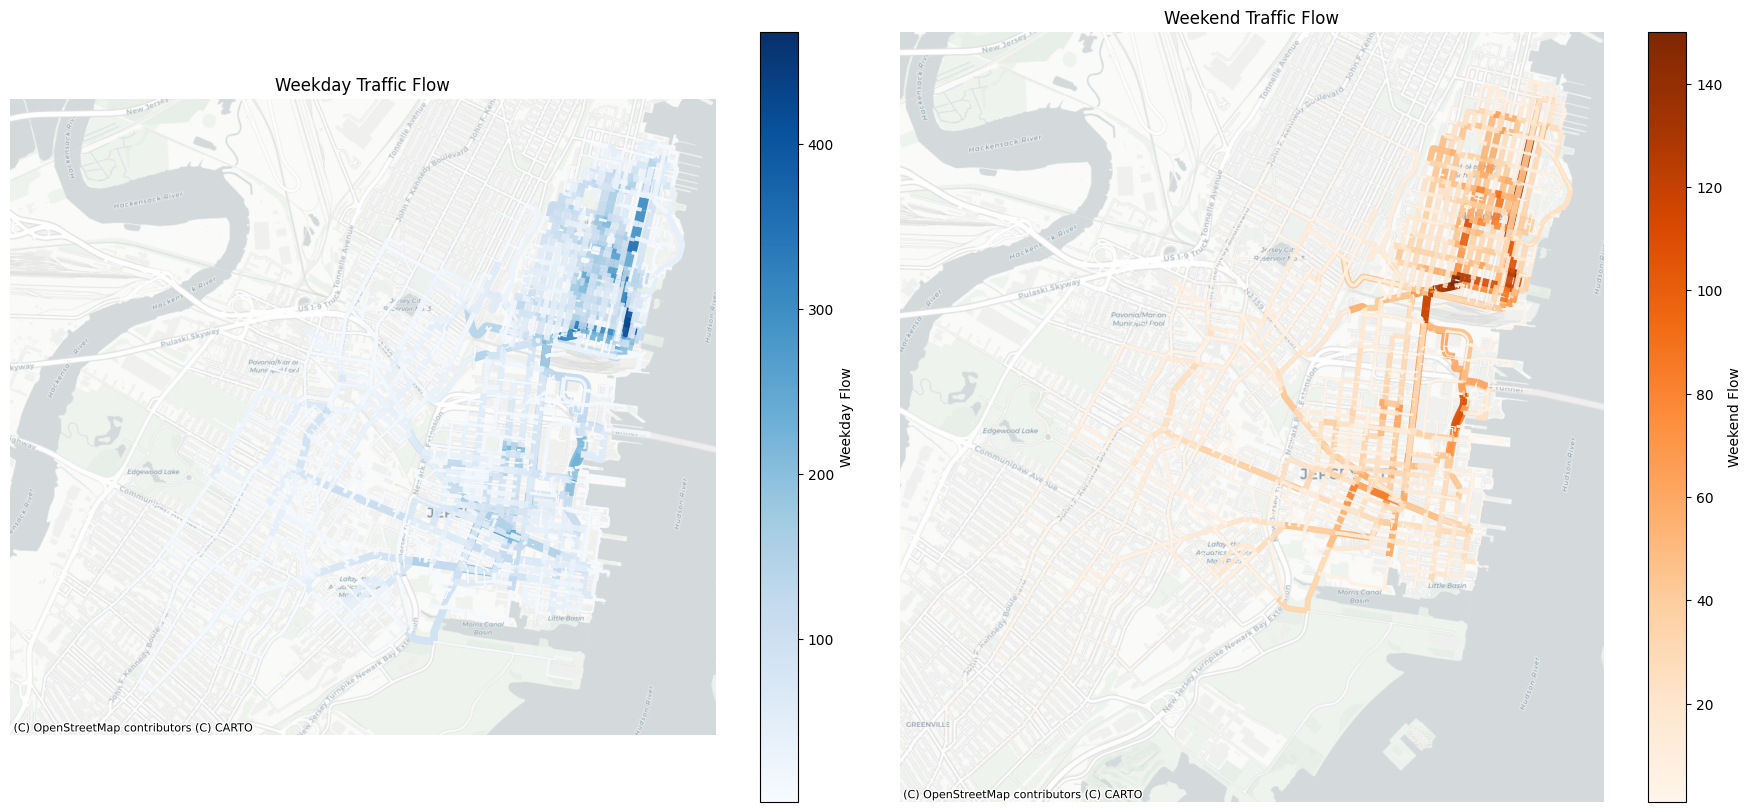

In [52]:
import matplotlib.pyplot as plt
import contextily as ctx
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# -------- WEEKDAY --------
weekday_web.plot(
    ax=axes[0],
    column="flow",
    cmap="Blues",
    linewidth=np.log1p(weekday_web["flow"]) * 1.2,
    alpha=0.9,
    legend=True,
    legend_kwds={'label': 'Weekday Flow'}
)

ctx.add_basemap(axes[0], source=ctx.providers.CartoDB.Positron)
axes[0].set_title("Weekday Traffic Flow")
axes[0].axis("off")

# -------- WEEKEND --------
weekend_web.plot(
    ax=axes[1],
    column="flow",
    cmap="Oranges",
    linewidth=np.log1p(weekend_web["flow"]) * 1.2,
    alpha=0.9,
    legend=True,
    legend_kwds={'label': 'Weekend Flow'}
)

ctx.add_basemap(axes[1], source=ctx.providers.CartoDB.Positron)
axes[1].set_title("Weekend Traffic Flow")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Interpretation — Weekday vs Weekend

Weekday traffic is more concentrated along major corridors, reflecting structured commuting patterns.

Weekend traffic shows a more distributed pattern, suggesting more flexible and recreational travel behavior.

The difference in edge counts and spatial distribution confirms that temporal factors significantly influence mobility patterns.

## Step 6B — Peak vs Off-Peak Traffic Flows

now lets check Trips which are classified based on time of day:

- Peak hours: 07:00–10:00 and 16:00–19:00
- Off-peak hours: all other times

This separation helps identify commuting peaks and differences in network usage across the day.

In [53]:
routes_gdf["hour"] = routes_gdf["started_at"].dt.hour

routes_gdf["is_peak"] = (
    (routes_gdf["hour"].between(7, 10)) |
    (routes_gdf["hour"].between(16, 19))
)

print(routes_gdf[["started_at", "hour", "is_peak"]].head())

               started_at  hour  is_peak
0 2025-09-09 17:37:42.905    17     True
1 2025-04-18 19:21:35.778    19     True
2 2025-09-05 08:12:26.464     8     True
3 2025-10-25 19:44:38.503    19     True
4 2025-11-30 21:42:37.110    21    False


In [54]:
peak_idx = routes_gdf[routes_gdf["is_peak"]].index
offpeak_idx = routes_gdf[~routes_gdf["is_peak"]].index

print("Peak trips:", len(peak_idx))
print("Off-peak trips:", len(offpeak_idx))

Peak trips: 5489
Off-peak trips: 4511


In [55]:
peak_counter = compute_flow([circle_routes[i] for i in peak_idx])
offpeak_counter = compute_flow([circle_routes[i] for i in offpeak_idx])

print("Peak edges:", len(peak_counter))
print("Off-peak edges:", len(offpeak_counter))

Peak edges: 4883
Off-peak edges: 4882


In [56]:
peak_gdf = counter_to_gdf(peak_counter)
offpeak_gdf = counter_to_gdf(offpeak_counter)

peak_web = peak_gdf.to_crs(epsg=3857)
offpeak_web = offpeak_gdf.to_crs(epsg=3857)

print("Peak edges (gdf):", len(peak_gdf))
print("Off-peak edges (gdf):", len(offpeak_gdf))

Peak edges (gdf): 4883
Off-peak edges (gdf): 4882


In [62]:
print("Peak mean:", peak_web["flow"].mean())
print("Off-peak mean:", offpeak_web["flow"].mean())

print("Peak max:", peak_web["flow"].max())
print("Off-peak max:", offpeak_web["flow"].max())

Peak mean: 26.212983821421258
Off-peak mean: 22.097091356001638
Peak max: 353
Off-peak max: 253


In [64]:
top_peak = peak_web.nlargest(50, "flow")

top_peak.plot(
    ax=axes[0],
    color="black",
    linewidth=2,
    label="Top Corridors"
)

<Axes: title={'center': 'Peak Traffic Flow'}>

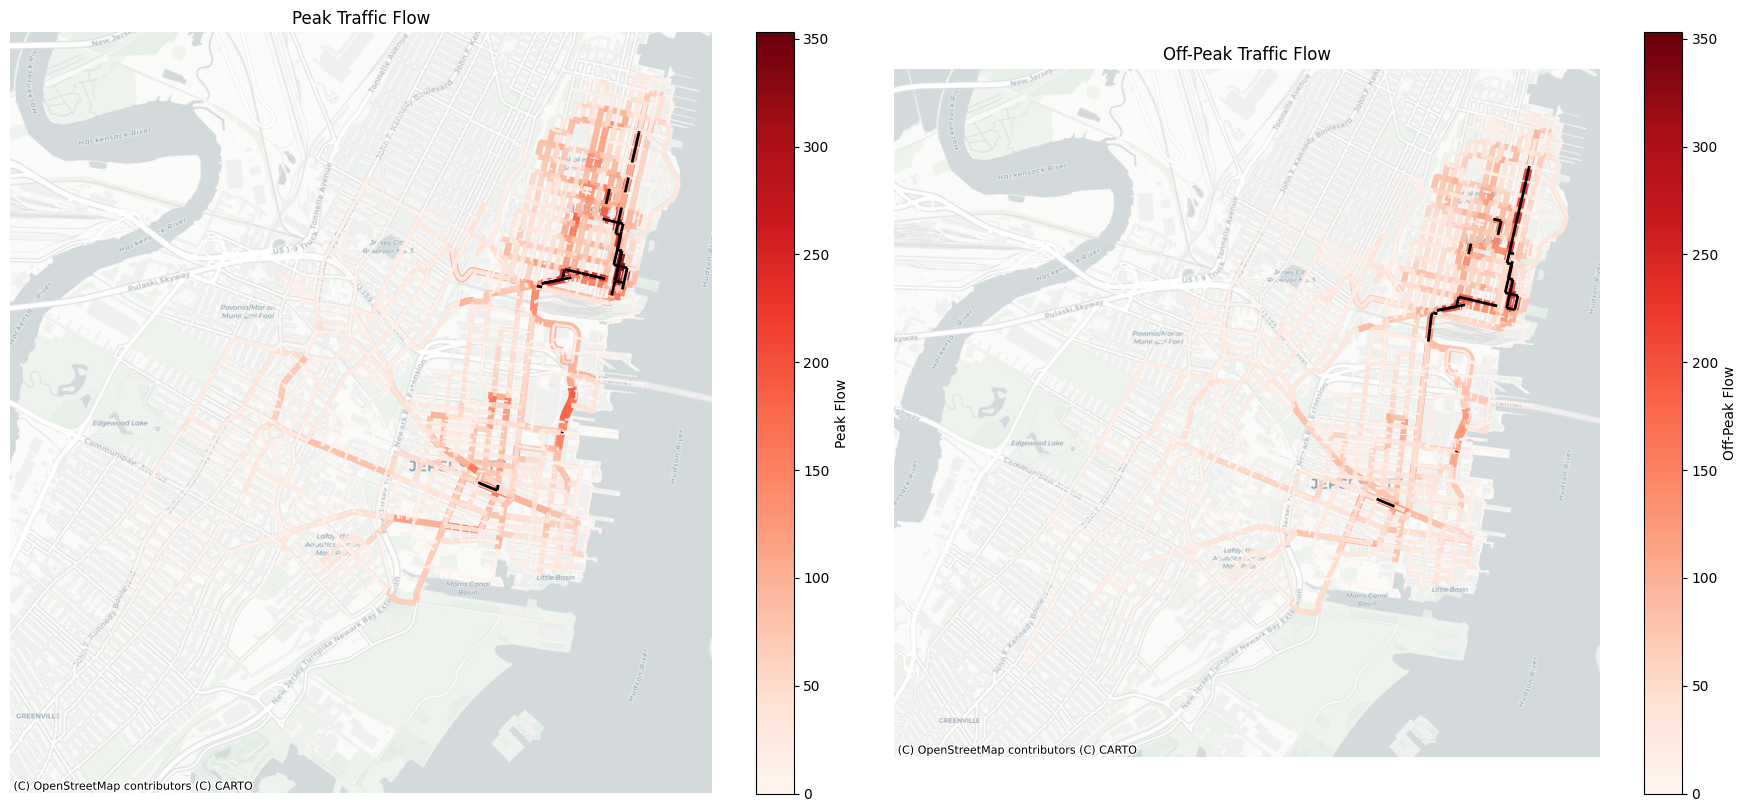

In [63]:
import matplotlib.pyplot as plt
import contextily as ctx
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# -------- SAME COLOR SCALE (IMPORTANT) --------
vmax = max(peak_web["flow"].max(), offpeak_web["flow"].max())

# -------- PEAK --------
peak_web.plot(
    ax=axes[0],
    column="flow",
    cmap="Reds",
    linewidth=np.log1p(peak_web["flow"]) * 1.0,
    alpha=0.9,
    vmin=0,
    vmax=vmax,
    legend=True,
    legend_kwds={'label': 'Peak Flow'}
)

# Highlight top corridors
top_peak = peak_web.nlargest(50, "flow")
top_peak.plot(
    ax=axes[0],
    color="black",
    linewidth=2,
    label="Top Corridors"
)

ctx.add_basemap(axes[0], source=ctx.providers.CartoDB.Positron)
axes[0].set_title("Peak Traffic Flow")
axes[0].axis("off")

# -------- OFF-PEAK --------
offpeak_web.plot(
    ax=axes[1],
    column="flow",
    cmap="Reds",
    linewidth=np.log1p(offpeak_web["flow"]) * 1.0,
    alpha=0.9,
    vmin=0,
    vmax=vmax,
    legend=True,
    legend_kwds={'label': 'Off-Peak Flow'}
)

# Highlight top corridors
top_offpeak = offpeak_web.nlargest(50, "flow")
top_offpeak.plot(
    ax=axes[1],
    color="black",
    linewidth=2,
    label="Top Corridors"
)

ctx.add_basemap(axes[1], source=ctx.providers.CartoDB.Positron)
axes[1].set_title("Off-Peak Traffic Flow")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Final Interpretation — Peak vs Off-Peak Traffic Flows

The comparison between peak and off-peak traffic flows reveals clear temporal variations in mobility patterns.

Peak-hour traffic exhibits higher overall intensity, with a mean flow of approximately 26.2 trips per segment compared to 22.1 during off-peak periods. The maximum observed flow during peak hours (353 trips) is also significantly higher than during off-peak periods (253 trips), confirming increased demand during commuting times.

Spatially, peak-hour traffic is more concentrated along major corridors, indicating structured commuting behavior during morning and evening periods. These corridors likely represent key routes connecting high-demand origin and destination areas.

In contrast, off-peak traffic is more evenly distributed across the network, reflecting more flexible and less time-constrained travel behavior.

The use of a consistent color scale across both maps ensures a fair comparison, highlighting that peak flows are not only more concentrated but also higher in magnitude.

Additionally, the persistence of certain high-flow corridors in both peak and off-peak conditions suggests the presence of structurally important routes within the network that serve as primary mobility connectors.

In [60]:
flow_gdf.to_file("flow_data.gpkg", driver="GPKG")

In [61]:
print(flow_gdf.columns)

Index(['u', 'v', 'total_flow', 'geometry', 'length_m'], dtype='str')


## conclusion 

Now the flow data has been saved as .gpkg file format to further help in analysis of the emission modelling task.